<a href="https://colab.research.google.com/github/dochieng014-code/breast-cancer-immune-stemness-survival/blob/main/TNBC_differential_expression_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Differential expression in TNBC: TCGA-BRCA, replicated in METABRIC
Run top to bottom. After Cell 1, restart the session (Runtime > Restart session), then continue from Cell 2.

In [ ]:
!pip install -q "pandas==2.2.3" pydeseq2 gseapy

## Setup
Mount Drive, set the output folder, and define the enrichment helper.

In [ ]:
import os, io, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
import gseapy as gp

drive.mount("/content/drive")
OUT = "/content/drive/MyDrive/tnbc_project"
os.makedirs(OUT, exist_ok=True)

RERUN_DESEQ = False   # True = fit DESeq2 again (15-45 min); False = reuse saved results if they exist

print("pandas", pd.__version__)
assert pd.__version__.startswith("2."), "Restart the session after Cell 1, then run this cell again."

GH = "https://media.githubusercontent.com/media/cBioPortal/datahub/master/public"

def read_url(url):
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text), sep="\t", comment="#")

def hallmark(genes, background, label):
    e = gp.enrich(gene_list=genes, gene_sets="MSigDB_Hallmark_2020",
                  background=background, outdir=None)
    out = e.results
    out = out[out["Adjusted P-value"] < 0.05].sort_values("Adjusted P-value")
    out.to_csv(f"{OUT}/enrichment_{label}.csv", index=False)
    print(f"\n=== {label}: {len(genes)} genes, {len(out)} Hallmark sets with adj p < 0.05 ===")
    cols = [c for c in ["Term", "Overlap", "Adjusted P-value"] if c in out.columns]
    print(out[cols].head(10).to_string(index=False))
    return out

Mounted at /content/drive
pandas 2.2.3


## 1. TCGA: define TNBC from receptor status
Receptor status comes from the original TCGA breast study (brca_tcga) and is matched by patient ID to the PanCancer Atlas patients.
Rule: TNBC = ER, PR and HER2 all negative. Non-TNBC = at least one positive. Missing or unresolved = excluded. Males excluded.

In [ ]:
pat = read_url(f"{GH}/brca_tcga_pan_can_atlas_2018/data_clinical_patient.txt")
old = read_url(f"{GH}/brca_tcga/data_clinical_patient.txt")

cols_needed = ["ER_STATUS_BY_IHC", "PR_STATUS_BY_IHC", "IHC_HER2", "HER2_FISH_STATUS"]
rec = old[["PATIENT_ID"] + cols_needed].drop_duplicates("PATIENT_ID")
m = pat[["PATIENT_ID", "SEX", "SUBTYPE"]].merge(rec, on="PATIENT_ID", how="left")

def clean(col):
    return m[col].astype(str).str.strip().str.lower()

er, pr = clean("ER_STATUS_BY_IHC"), clean("PR_STATUS_BY_IHC")
her2, fish = clean("IHC_HER2"), clean("HER2_FISH_STATUS")
female = clean("SEX") == "female"

her2_neg = (her2 == "negative") | ((her2 == "equivocal") & (fish == "negative"))
her2_pos = (her2 == "positive") | ((her2 == "equivocal") & (fish == "positive"))

tnbc = female & (er == "negative") & (pr == "negative") & her2_neg
non_tnbc = female & ((er == "positive") | (pr == "positive") | her2_pos)

m["group"] = "excluded"
m.loc[tnbc, "group"] = "TNBC"
m.loc[non_tnbc, "group"] = "non-TNBC"

print(m["group"].value_counts())   # expect non-TNBC 840, TNBC 142, excluded 102
print("\nSanity check against PAM50:")
print(pd.crosstab(m["group"], m["SUBTYPE"].fillna("missing")))
m[["PATIENT_ID", "group"]].to_csv(f"{OUT}/tcga_groups_receptor.csv", index=False)

group
non-TNBC    840
TNBC        142
excluded    102
Name: count, dtype: int64

Sanity check against PAM50:
SUBTYPE   BRCA_Basal  BRCA_Her2  BRCA_LumA  BRCA_LumB  BRCA_Normal  missing
group                                                                      
TNBC             104         11          3          1            7       16
excluded          32          9         23         13            6       19
non-TNBC          35         58        473        183           23       68


## 2. TCGA: expression counts
GDC STAR counts from UCSC Xena, stored as log2(count + 1). I reverse that, check that the result is whole numbers, keep one primary tumour per patient, and keep only TNBC and non-TNBC patients.

In [ ]:
cnt_path = f"{OUT}/tcga_counts_tnbc_vs_non.csv"
meta_path = f"{OUT}/tcga_meta_tnbc_vs_non.csv"

if os.path.exists(cnt_path) and os.path.exists(meta_path):
    print("Counts and metadata already built; skipping.")
else:
    url = "https://gdc-hub.s3.us-east-1.amazonaws.com/download/TCGA-BRCA.star_counts.tsv.gz"
    fn = "TCGA-BRCA.star_counts.tsv.gz"
    if not os.path.exists(fn) or os.path.getsize(fn) < 100_000_000:
        print("Downloading about 139 MB to Colab...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(fn, "wb") as f:
                for chunk in r.iter_content(1024 * 1024):
                    f.write(chunk)

    expr = pd.read_csv(fn, sep="\t", index_col=0, compression="gzip")
    print("Expression (genes x samples):", expr.shape)
    test = 2 ** expr.iloc[:2000, :10].values - 1
    print("Share of values within 0.01 of a whole number:",
          float(np.mean(np.abs(test - np.round(test)) < 0.01)))

    groups = pd.read_csv(f"{OUT}/tcga_groups_receptor.csv")
    samples = pd.Series(expr.columns)
    tp = pd.DataFrame({"sample": samples[samples.str[13:15] == "01"].tolist()})
    tp["PATIENT_ID"] = tp["sample"].str[:12]
    tp = tp.sort_values("sample").drop_duplicates("PATIENT_ID", keep="first")
    final = tp.merge(groups, on="PATIENT_ID", how="inner")

    use = final[final["group"].isin(["TNBC", "non-TNBC"])].copy()
    counts = np.rint(2 ** expr[use["sample"]] - 1).astype(int)
    counts.columns = use["PATIENT_ID"].values
    meta = use.set_index("PATIENT_ID")[["sample", "group"]]
    print("Counts:", counts.shape, "| Groups:", meta["group"].value_counts().to_dict())  # expect 60660 x 980; 839 / 141
    counts.to_csv(cnt_path)
    meta.to_csv(meta_path)

Counts and metadata already built; skipping.


## 3. TCGA: differential expression (PyDESeq2)
Genes kept: at least 10 counts in at least as many samples as the smaller group. Design ~group, contrast TNBC vs non-TNBC. Fold changes are not shrunk.

In [ ]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

res_path = f"{OUT}/deseq2_tnbc_vs_non.csv"

if RERUN_DESEQ or not os.path.exists(res_path):
    counts = pd.read_csv(cnt_path, index_col=0)
    meta = pd.read_csv(meta_path, index_col=0)

    min_samples = int(meta["group"].value_counts().min())   # 141
    keep = (counts >= 10).sum(axis=1) >= min_samples
    counts_f = counts.loc[keep]
    print("Genes before:", counts.shape[0], "| after filtering:", counts_f.shape[0])   # expect 24684

    dds_counts = counts_f.T.astype(np.int64)
    dds_meta = meta[["group"]].copy()
    dds_meta["group"] = dds_meta["group"].astype(str).astype("category")
    dds_counts.index = dds_counts.index.astype(str)
    dds_meta.index = dds_meta.index.astype(str)

    inference = DefaultInference(n_cpus=2)
    dds = DeseqDataSet(counts=dds_counts, metadata=dds_meta, design="~group", inference=inference)
    dds.deseq2()
    ds = DeseqStats(dds, contrast=["group", "TNBC", "non-TNBC"], inference=inference)
    ds.summary()
    ds.results_df.to_csv(res_path)
else:
    print("Reusing saved DESeq2 results.")

res = pd.read_csv(res_path, index_col=0)
print("Genes tested:", res.shape[0])
print("padj < 0.05:", int((res["padj"] < 0.05).sum()))
sig = (res["padj"] < 0.05) & (res["log2FoldChange"].abs() > 1)
print("padj < 0.05 and |log2FC| > 1:", int(sig.sum()),
      "| higher in TNBC:", int((sig & (res["log2FoldChange"] > 0)).sum()),
      "| lower in TNBC:", int((sig & (res["log2FoldChange"] < 0)).sum()))

Reusing saved DESeq2 results.
Genes tested: 24684
padj < 0.05: 19221
padj < 0.05 and |log2FC| > 1: 4659 | higher in TNBC: 2413 | lower in TNBC: 2246


## 4. TCGA: gene symbols and the top genes
Ensembl IDs mapped with the GENCODE v36 annotation file from Xena. Check: ESR1 and GATA3 should appear under their names.

In [ ]:
u = "https://gdc-hub.s3.us-east-1.amazonaws.com/download/gencode.v36.annotation.gtf.gene.probemap"
pm = pd.read_csv(io.StringIO(requests.get(u, timeout=120).text), sep="\t")
mapping = pm.set_index("id")["gene"]
mapping = mapping[~mapping.index.duplicated()]

res["symbol"] = res.index.map(mapping)
print("Genes with a symbol:", int(res["symbol"].notna().sum()), "of", len(res))
for eid in ["ENSG00000091831", "ENSG00000107485"]:
    print(res.loc[res.index.str.startswith(eid), ["symbol", "log2FoldChange", "padj"]])

sig_df = res[(res["padj"] < 0.05) & (res["log2FoldChange"].abs() > 1)]
cols = ["symbol", "log2FoldChange", "padj"]
print("\nTop 15 higher in TNBC:")
print(sig_df[sig_df["log2FoldChange"] > 0].sort_values("padj").head(15)[cols])
print("\nTop 15 lower in TNBC:")
print(sig_df[sig_df["log2FoldChange"] < 0].sort_values("padj").head(15)[cols])
res.to_csv(f"{OUT}/deseq2_tnbc_vs_non_annotated.csv")

Genes with a symbol: 24684 of 24684
                   symbol  log2FoldChange           padj
Ensembl_ID                                              
ENSG00000091831.24   ESR1       -5.248925  1.407503e-280
                   symbol  log2FoldChange           padj
Ensembl_ID                                              
ENSG00000107485.18  GATA3       -3.204686  1.583094e-205

Top 15 higher in TNBC:
                        symbol  log2FoldChange           padj
Ensembl_ID                                                   
ENSG00000158887.19         MPZ        4.079195  4.751742e-186
ENSG00000134802.18     SLC43A3        2.054221  1.568132e-131
ENSG00000112280.17      COL9A1        5.848424  3.174198e-130
ENSG00000253348.1   AC008514.1        3.774364  7.056537e-128
ENSG00000154548.9       SRSF12        3.124012  2.031429e-127
ENSG00000134873.10      CLDN10        4.900263  1.404958e-121
ENSG00000213064.10      SFT2D2        1.530506  1.683179e-115
ENSG00000135912.11       TTLL4        1.

## 5. TCGA: sanity check and volcano plot
Expected: ESR1, GATA3, FOXA1 lower in TNBC; KRT5, KRT17 higher.

ESR1: log2FC -5.25, padj 1.41e-280
GATA3: log2FC -3.20, padj 1.58e-205
FOXA1: log2FC -2.92, padj 2.10e-125
KRT5: log2FC 2.50, padj 6.92e-29
KRT17: log2FC 2.36, padj 5.08e-30


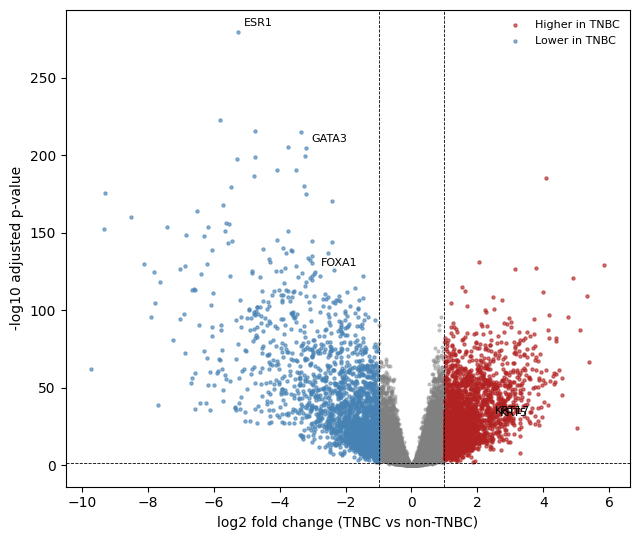

In [ ]:
checks = {"ESR1": "ENSG00000091831", "GATA3": "ENSG00000107485",
          "FOXA1": "ENSG00000129514", "KRT5": "ENSG00000186081",
          "KRT17": "ENSG00000128422"}
for name, eid in checks.items():
    hit = res[res.index.str.startswith(eid)]
    if len(hit):
        r_ = hit.iloc[0]
        print(f"{name}: log2FC {r_.log2FoldChange:.2f}, padj {r_.padj:.2e}")

r = res.dropna(subset=["padj"]).copy()
r["nlp"] = -np.log10(r["padj"].clip(lower=1e-300))
s = (r["padj"] < 0.05) & (r["log2FoldChange"].abs() > 1)
up, dn = s & (r["log2FoldChange"] > 0), s & (r["log2FoldChange"] < 0)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(r.loc[~s, "log2FoldChange"], r.loc[~s, "nlp"], s=4, alpha=0.4, color="grey")
ax.scatter(r.loc[up, "log2FoldChange"], r.loc[up, "nlp"], s=5, alpha=0.6, color="firebrick", label="Higher in TNBC")
ax.scatter(r.loc[dn, "log2FoldChange"], r.loc[dn, "nlp"], s=5, alpha=0.6, color="steelblue", label="Lower in TNBC")
for name, eid in checks.items():
    hit = r[r.index.str.startswith(eid)]
    if len(hit):
        ax.annotate(name, (hit["log2FoldChange"].iloc[0], hit["nlp"].iloc[0]),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axvline(-1, ls="--", lw=0.6, color="black"); ax.axvline(1, ls="--", lw=0.6, color="black")
ax.axhline(-np.log10(0.05), ls="--", lw=0.6, color="black")
ax.set_xlabel("log2 fold change (TNBC vs non-TNBC)")
ax.set_ylabel("-log10 adjusted p-value")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/volcano_tnbc_vs_non.png", dpi=200)
plt.show()

## 6. TCGA: pathway enrichment (MSigDB Hallmark)
Over-representation test with the genes I actually tested as background (not the whole genome). GO Biological Process would not load, so only Hallmark is reported.

In [ ]:
rr = res.dropna(subset=["symbol"]).copy()
rr["symbol"] = rr["symbol"].str.upper()
rr = rr.sort_values("padj").drop_duplicates("symbol", keep="first")

background_tcga = rr["symbol"].tolist()
sg = rr[(rr["padj"] < 0.05) & (rr["log2FoldChange"].abs() > 1)]
up_genes = sg.loc[sg["log2FoldChange"] > 0, "symbol"].tolist()
dn_genes = sg.loc[sg["log2FoldChange"] < 0, "symbol"].tolist()
print("Background:", len(background_tcga), "| higher:", len(up_genes), "| lower:", len(dn_genes))  # 24659 | 2412 | 2243

_ = hallmark(up_genes, background_tcga, "higher_in_TNBC_tested_background")
_ = hallmark(dn_genes, background_tcga, "lower_in_TNBC_tested_background")

Background: 24659 | higher: 2412 | lower: 2243

=== higher_in_TNBC_tested_background: 2412 genes, 5 Hallmark sets with adj p < 0.05 ===
                 Term  Adjusted P-value
    KRAS Signaling Dn      4.982331e-08
      G2-M Checkpoint      3.300156e-05
          E2F Targets      3.642739e-04
      Spermatogenesis      1.444020e-03
Inflammatory Response      2.708458e-02

=== lower_in_TNBC_tested_background: 2243 genes, 3 Hallmark sets with adj p < 0.05 ===
                   Term  Adjusted P-value
Estrogen Response Early      8.396944e-30
 Estrogen Response Late      6.501157e-21
    Pancreas Beta Cells      8.765059e-03


## 7. METABRIC: define TNBC
Same rule, using ER_STATUS, PR_STATUS and HER2_STATUS from the sample file. Checks: three-gene classifier and claudin subtype.

In [ ]:
MB = f"{GH}/brca_metabric"
mpat = read_url(f"{MB}/data_clinical_patient.txt")
msmp = read_url(f"{MB}/data_clinical_sample.txt")

mm = msmp[["PATIENT_ID", "SAMPLE_ID", "ER_STATUS", "PR_STATUS", "HER2_STATUS"]].merge(
    mpat[["PATIENT_ID", "THREEGENE", "CLAUDIN_SUBTYPE"]], on="PATIENT_ID", how="left")

def norm(col):
    return mm[col].astype(str).str.strip().str.lower()

er, pr, her2 = norm("ER_STATUS"), norm("PR_STATUS"), norm("HER2_STATUS")
pos = lambda s_: s_.str.startswith("pos")
neg = lambda s_: s_.str.startswith("neg")

tnbc = neg(er) & neg(pr) & neg(her2)
non_tnbc = pos(er) | pos(pr) | pos(her2)

mm["group"] = "excluded"
mm.loc[tnbc, "group"] = "TNBC"
mm.loc[non_tnbc, "group"] = "non-TNBC"

print(mm["group"].value_counts())   # expect non-TNBC 1979, TNBC 320, excluded 210
print("\nvs THREEGENE:")
print(pd.crosstab(mm["group"], mm["THREEGENE"].fillna("missing")))
print("\nvs CLAUDIN_SUBTYPE:")
print(pd.crosstab(mm["group"], mm["CLAUDIN_SUBTYPE"].fillna("missing")))
mm[["PATIENT_ID", "SAMPLE_ID", "group"]].to_csv(f"{OUT}/metabric_groups.csv", index=False)

group
non-TNBC    1979
TNBC         320
excluded     210
Name: count, dtype: int64

vs THREEGENE:
THREEGENE  ER+/HER2- High Prolif  ER+/HER2- Low Prolif  ER-/HER2-  HER2+  \
group                                                                      
TNBC                           7                     9        246      4   
excluded                       0                     0          0      0   
non-TNBC                     610                   631         63    194   

THREEGENE  missing  
group               
TNBC            54  
excluded       210  
non-TNBC       481  

vs CLAUDIN_SUBTYPE:
CLAUDIN_SUBTYPE  Basal  Her2  LumA  LumB  NC  Normal  claudin-low  missing
group                                                                     
TNBC               157    30     3     0   0      11          119        0
excluded             0     0     0     0   0       0            0      210
non-TNBC            52   194   697   475   6     137           99      319


## 8. METABRIC: expression
Illumina microarray log2 intensities (about 689 MB; downloaded to Colab, not to the phone). Duplicate gene symbols are averaged.

In [ ]:
mexpr_path = f"{OUT}/metabric_expr_tnbc_vs_non.csv.gz"
mmeta_path = f"{OUT}/metabric_meta_tnbc_vs_non.csv"

if os.path.exists(mexpr_path) and os.path.exists(mmeta_path):
    print("METABRIC expression already prepared; skipping.")
else:
    url = f"{MB}/data_mrna_illumina_microarray.txt"
    fn = "metabric_expression.txt"
    if not os.path.exists(fn) or os.path.getsize(fn) < 600_000_000:
        print("Downloading about 689 MB to Colab...")
        with requests.get(url, stream=True, timeout=300) as r:
            r.raise_for_status()
            with open(fn, "wb") as f:
                for chunk in r.iter_content(4 * 1024 * 1024):
                    f.write(chunk)

    mx = pd.read_csv(fn, sep="\t", comment="#")
    mx = mx.drop(columns=[c for c in ["Entrez_Gene_Id"] if c in mx.columns])
    mx = mx.dropna(subset=["Hugo_Symbol"])
    mx = mx.groupby("Hugo_Symbol").mean().astype("float32")
    print("Genes x samples:", mx.shape,
          "| value range:", float(np.nanmin(mx.values)), "to", float(np.nanmax(mx.values)))

    mg = pd.read_csv(f"{OUT}/metabric_groups.csv")
    mg = mg[mg["group"].isin(["TNBC", "non-TNBC"])]
    have = mg[mg["SAMPLE_ID"].isin(mx.columns)].copy()
    print("With expression and a group:", have["group"].value_counts().to_dict())   # expect 320 / 1660
    mx[have["SAMPLE_ID"]].to_csv(mexpr_path, compression="gzip")
    have.to_csv(mmeta_path, index=False)

METABRIC expression already prepared; skipping.


## 9. METABRIC: differential expression
Welch's t-test per gene with Benjamini-Hochberg correction. Effect size = difference in mean log2 intensity. This is not the full limma method.

In [ ]:
from scipy import stats
from statsmodels.stats.multitest import multipletests

mx = pd.read_csv(mexpr_path, index_col=0)
mmeta = pd.read_csv(mmeta_path)
t_ids = mmeta.loc[mmeta["group"] == "TNBC", "SAMPLE_ID"]
n_ids = mmeta.loc[mmeta["group"] == "non-TNBC", "SAMPLE_ID"]

a, b = mx[t_ids].values, mx[n_ids].values
t, p = stats.ttest_ind(a, b, axis=1, equal_var=False, nan_policy="omit")

res_m = pd.DataFrame({"log2FC": np.nanmean(a, axis=1) - np.nanmean(b, axis=1),
                      "t": t, "pvalue": p}, index=mx.index)
ok = res_m["pvalue"].notna()
res_m["padj"] = np.nan
res_m.loc[ok, "padj"] = multipletests(res_m.loc[ok, "pvalue"], method="fdr_bh")[1]
res_m.to_csv(f"{OUT}/metabric_de_tnbc_vs_non.csv")

print("Genes tested:", int(ok.sum()), "| padj < 0.05:", int((res_m["padj"] < 0.05).sum()))
sm = (res_m["padj"] < 0.05) & (res_m["log2FC"].abs() > 1)
print("padj < 0.05 and |difference| > 1:", int(sm.sum()),
      "| higher:", int((sm & (res_m["log2FC"] > 0)).sum()),
      "| lower:", int((sm & (res_m["log2FC"] < 0)).sum()))
for g in ["ESR1", "GATA3", "FOXA1", "KRT5", "KRT17"]:
    if g in res_m.index:
        print(f"{g}: difference {res_m.loc[g, 'log2FC']:.2f}, padj {res_m.loc[g, 'padj']:.2e}")

Genes tested: 20384 | padj < 0.05: 12708
padj < 0.05 and |difference| > 1: 355 | higher: 131 | lower: 224
ESR1: difference -4.05, padj 0.00e+00
GATA3: difference -2.93, padj 1.16e-176
FOXA1: difference -3.84, padj 2.94e-108
KRT5: difference 1.36, padj 3.53e-34
KRT17: difference 1.56, padj 1.08e-34


## 10. Replication: TCGA vs METABRIC
Platforms differ, so I compare effect sizes and direction, not p-values.

Genes in both cohorts: 16570
Same direction, all shared genes: 83.1%
Spearman correlation of effect sizes: 0.78

TCGA-significant genes also in METABRIC: 2976
  same direction: 94.2%
  same direction and METABRIC padj < 0.05: 2473 (83.1%)
  higher in TNBC: 1622 genes in TCGA, 1366 replicate
  lower in TNBC: 1354 genes in TCGA, 1107 replicate


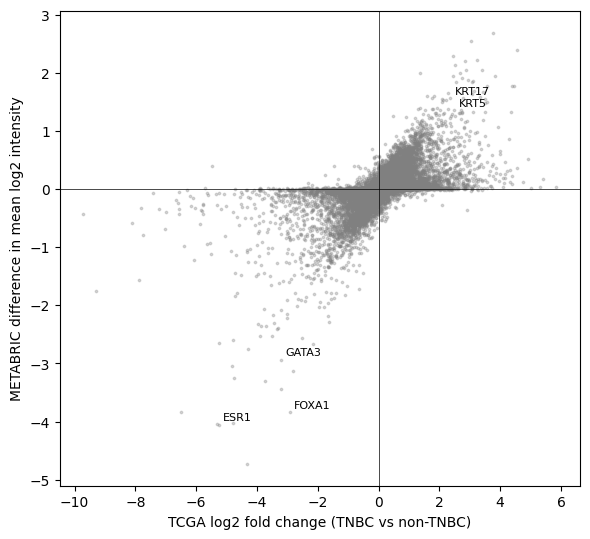

In [ ]:
from scipy.stats import spearmanr

tc = res.dropna(subset=["symbol", "padj"]).copy()
tc["symbol"] = tc["symbol"].str.upper()
tc = tc.sort_values("padj").drop_duplicates("symbol")
tc = tc.set_index("symbol")[["log2FoldChange", "padj"]].add_prefix("tcga_")

mb = res_m.copy()
mb.index = mb.index.astype(str).str.upper()
mb = mb[~mb.index.duplicated()][["log2FC", "padj"]].add_prefix("meta_")

both = tc.join(mb, how="inner").dropna()
print("Genes in both cohorts:", len(both))   # 16570
same_all = np.sign(both["tcga_log2FoldChange"]) == np.sign(both["meta_log2FC"])
print(f"Same direction, all shared genes: {same_all.mean():.1%}")
print(f"Spearman correlation of effect sizes: "
      f"{spearmanr(both['tcga_log2FoldChange'], both['meta_log2FC'])[0]:.2f}")

ts = both[(both["tcga_padj"] < 0.05) & (both["tcga_log2FoldChange"].abs() > 1)]
same = np.sign(ts["tcga_log2FoldChange"]) == np.sign(ts["meta_log2FC"])
rep = ts[same & (ts["meta_padj"] < 0.05)]
print(f"\nTCGA-significant genes also in METABRIC: {len(ts)}")
print(f"  same direction: {same.mean():.1%}")
print(f"  same direction and METABRIC padj < 0.05: {len(rep)} ({len(rep)/len(ts):.1%})")
for name, cond in [("higher in TNBC", ts["tcga_log2FoldChange"] > 0),
                   ("lower in TNBC", ts["tcga_log2FoldChange"] < 0)]:
    sub = ts[cond]
    print(f"  {name}: {len(sub)} genes in TCGA, {rep.index.isin(sub.index).sum()} replicate")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(both["tcga_log2FoldChange"], both["meta_log2FC"], s=3, alpha=0.3, color="grey")
for g in ["ESR1", "GATA3", "FOXA1", "KRT5", "KRT17"]:
    if g in both.index:
        ax.annotate(g, (both.loc[g, "tcga_log2FoldChange"], both.loc[g, "meta_log2FC"]),
                    fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, lw=0.5, color="black"); ax.axvline(0, lw=0.5, color="black")
ax.set_xlabel("TCGA log2 fold change (TNBC vs non-TNBC)")
ax.set_ylabel("METABRIC difference in mean log2 intensity")
plt.tight_layout()
plt.savefig(f"{OUT}/replication_scatter.png", dpi=200)
plt.show()

## 11. Genes that did not replicate, and pathways among those that did
Background for the enrichment: the genes tested in both cohorts.

In [ ]:
rep.to_csv(f"{OUT}/replicated_genes.csv")

opp = ts[~same].sort_values("tcga_padj")
opp_sig = opp[opp["meta_padj"] < 0.05]
same_not_sig = ts[same & (ts["meta_padj"] >= 0.05)]
print("Opposite direction in METABRIC:", len(opp), "| significant there too:", len(opp_sig))
print("Same direction but not significant in METABRIC:", len(same_not_sig))
print(opp_sig.sort_values("meta_padj").head(10).round(3))
pd.concat([opp.assign(reason="opposite direction"),
           same_not_sig.assign(reason="same direction, not significant")]
          ).to_csv(f"{OUT}/not_replicated_genes.csv")

bg_both = both.index.tolist()
_ = hallmark(rep.index[rep["tcga_log2FoldChange"] > 0].tolist(), bg_both, "replicated_higher_in_TNBC")
_ = hallmark(rep.index[rep["tcga_log2FoldChange"] < 0].tolist(), bg_both, "replicated_lower_in_TNBC")

Opposite direction in METABRIC: 173 | significant there too: 31
Same direction but not significant in METABRIC: 330
            tcga_log2FoldChange  tcga_padj  meta_log2FC  meta_padj
GTF2IRD2P1                2.090        0.0       -0.281        0.0
HTR2A                     1.541        0.0       -0.189        0.0
LGALS9C                  -1.759        0.0        0.249        0.0
MT1A                     -1.478        0.0        0.401        0.0
OIT3                      1.102        0.0       -0.088        0.0
POTEKP                   -5.465        0.0        0.403        0.0
CDH12                     1.536        0.0       -0.065        0.0
WNT16                     1.171        0.0       -0.082        0.0
LGALS9B                  -2.306        0.0        0.104        0.0
ASB16                    -1.348        0.0        0.166        0.0

=== replicated_higher_in_TNBC: 1366 genes, 13 Hallmark sets with adj p < 0.05 ===
                     Term  Adjusted P-value
          G2-M Check